# Experiment 10: K-Means Clustering

## Aim
To implement unsupervised clustering using the K-Means algorithm on the Student Performance dataset.

## Learning Outcomes
After completing this experiment, students will be able to:

1. Select appropriate student-performance features for clustering.
2. Standardize features before applying a distance-based algorithm.
3. Use the Elbow Method and Silhouette Score to choose a suitable value of $K$.
4. Train a K-Means clustering model.
5. Visualize clusters in two-dimensional PCA space.
6. Interpret cluster centres and student-performance profiles.

> **Important:** K-Means is an **unsupervised learning algorithm**. The `pass_fail` target is not used while creating clusters. It is used only at the end to compare the discovered clusters with the existing pass/fail label.

## 1. Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

Keep the Student Performance CSV file in the same folder as this notebook when working locally. The Kaggle path used in the earlier experiments is included below.

In [2]:
possible_paths = [
    "/kaggle/input/datasets/tahreemrashid/student-performance-dataset/student_performance.csv",
    "student_performance.csv",
    "./data/student_performance.csv"
]

DATA_PATH = next((path for path in possible_paths if os.path.exists(path)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Download/upload student_performance.csv and update possible_paths."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully from:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully from: /kaggle/input/datasets/tahreemrashid/student-performance-dataset/student_performance.csv
Dataset shape: (1000, 15)


,student_id,name,gender,age,class,teacher_id,subject,test1_score,test2_score,final_exam_score,final_grade_letter,attendance_percentage,study_hours_per_week,assignments_submitted,pass_fail
0,1,Carson Rivera,Female,14,9th,105,Math,23.5,40.5,50.5,F,70.2,3.1,56.7,0
1,2,Ashley Walters,Male,15,10th,107,Computer,77.7,80.6,82.3,B,85.3,6.9,81.0,1
2,3,Linda Robinson,Male,15,10th,103,English,75.0,73.4,64.5,C,83.1,4.3,66.3,1
3,4,Brandon James,Female,17,11th,117,Computer,46.7,53.1,51.2,F,74.1,0.4,44.9,0
4,5,Helen Grant,Female,16,10th,112,Science,38.0,57.3,47.6,F,73.8,1.4,49.9,0


## 3. Select Features for Clustering

We cluster students using measurable academic and engagement features:

- Test 1, Test 2 and final-exam scores
- Attendance percentage
- Weekly study hours
- Assignment-submission percentage

We exclude identifiers (`student_id`, `teacher_id`, `name`) because they do not describe student behaviour or performance. We also exclude `pass_fail` and `final_grade_letter` because these are outcome variables, not inputs for unsupervised clustering.

In [3]:
target_column = "pass_fail"
feature_columns = [
    "test1_score",
    "test2_score",
    "final_exam_score",
    "attendance_percentage",
    "study_hours_per_week",
    "assignments_submitted"
]

missing_features = [col for col in feature_columns if col not in df.columns]
if missing_features:
    raise ValueError(f"Expected feature columns not found: {missing_features}")

X = df[feature_columns].copy()
y = df[target_column].copy() if target_column in df.columns else None

print("Features selected for K-Means:")
print(feature_columns)
display(X.head())

Features selected for K-Means:
['test1_score', 'test2_score', 'final_exam_score', 'attendance_percentage', 'study_hours_per_week', 'assignments_submitted']


,test1_score,test2_score,final_exam_score,attendance_percentage,study_hours_per_week,assignments_submitted
0,23.5,40.5,50.5,70.2,3.1,56.7
1,77.7,80.6,82.3,85.3,6.9,81.0
2,75.0,73.4,64.5,83.1,4.3,66.3
3,46.7,53.1,51.2,74.1,0.4,44.9
4,38.0,57.3,47.6,73.8,1.4,49.9


## 4. Check and Handle Missing Values

K-Means cannot work with missing values. Median imputation is used for any missing numerical observation.

In [4]:
print("Missing values before imputation:")
display(X.isnull().sum().to_frame("Missing Values"))

imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X), columns=feature_columns, index=X.index
)

print("Total missing values after imputation:", int(X_imputed.isnull().sum().sum()))

Missing values before imputation:


,Missing Values
test1_score,0
test2_score,0
final_exam_score,0
attendance_percentage,0
study_hours_per_week,0
assignments_submitted,0


Total missing values after imputation: 0


## 5. Standardize the Features

K-Means assigns points to the nearest centroid. Therefore, variables with large ranges can dominate the distance calculation. We standardize each feature:

$$z = \frac{x-\mu}{\sigma}$$

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_columns, index=X.index)

print("Feature means after scaling (approximately 0):")
display(X_scaled_df.mean().round(3).to_frame("Mean"))

Feature means after scaling (approximately 0):


,Mean
test1_score,-0.0
test2_score,-0.0
final_exam_score,-0.0
attendance_percentage,-0.0
study_hours_per_week,0.0
assignments_submitted,0.0


## 6. K-Means Concept

K-Means divides observations into $K$ groups by repeatedly:

1. Initializing $K$ centroids.
2. Assigning every student to the nearest centroid.
3. Updating each centroid as the mean of its assigned students.
4. Repeating until the centroids no longer change substantially.

The **inertia** (within-cluster sum of squares) measures compactness:

$$\text{Inertia} = \sum_{k=1}^{K}\sum_{x_i\in C_k}\|x_i-\mu_k\|^2$$

## 7. Elbow Method

We fit K-Means for several values of $K$. As $K$ increases, inertia always decreases. The preferred value is often near the “elbow”, where the improvement begins to slow down.

In [6]:
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

selection_table = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})
display(selection_table.round(3))

,K,Inertia,Silhouette Score
0,2,2965.550,0.393
1,3,2196.558,0.300
2,4,1880.721,0.238
3,5,1717.443,0.199
4,6,1580.230,0.192
5,7,1482.642,0.186
6,8,1412.304,0.175


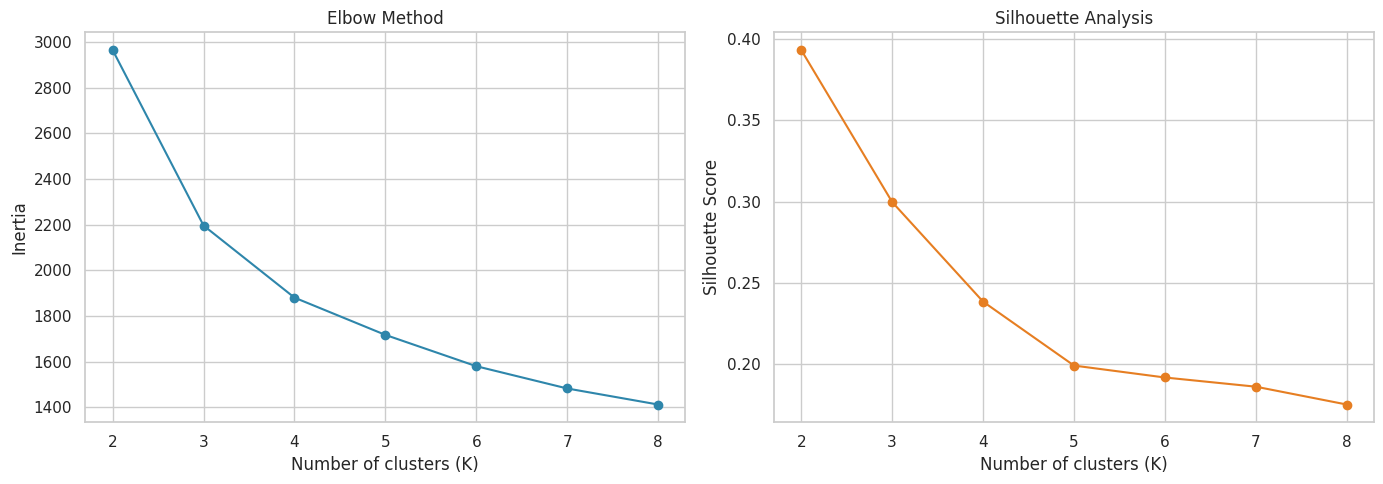

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), inertias, marker="o", color="#2E86AB")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

axes[1].plot(list(k_values), silhouette_scores, marker="o", color="#E67E22")
axes[1].set_title("Silhouette Analysis")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()

## 8. Choose the Number of Clusters

For this student-performance dataset, we use **K = 3** to obtain interpretable groups such as comparatively high-, moderate-, and low-performance/engagement profiles. You may change this value after examining the elbow and silhouette plots.

In [8]:
optimal_k = 3
print(f"Selected number of clusters (K): {optimal_k}")

Selected number of clusters (K): 3


## 9. Train the K-Means Model and Assign Cluster Labels

In [9]:
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

clustered_df = df.copy()
clustered_df["cluster"] = cluster_labels

print("Model inertia:", round(kmeans.inertia_, 3))
print("Silhouette score:", round(silhouette_score(X_scaled, cluster_labels), 3))
print("\nStudents in each cluster:")
display(clustered_df["cluster"].value_counts().sort_index().to_frame("Number of Students"))

Model inertia: 2196.558
Silhouette score: 0.3

Students in each cluster:


,Number of Students
cluster,
0,242
1,334
2,424


## 10. Visualize Clusters Using PCA

The original clustering is performed using all six standardized features. PCA is used only to display the clusters on a two-dimensional plot.

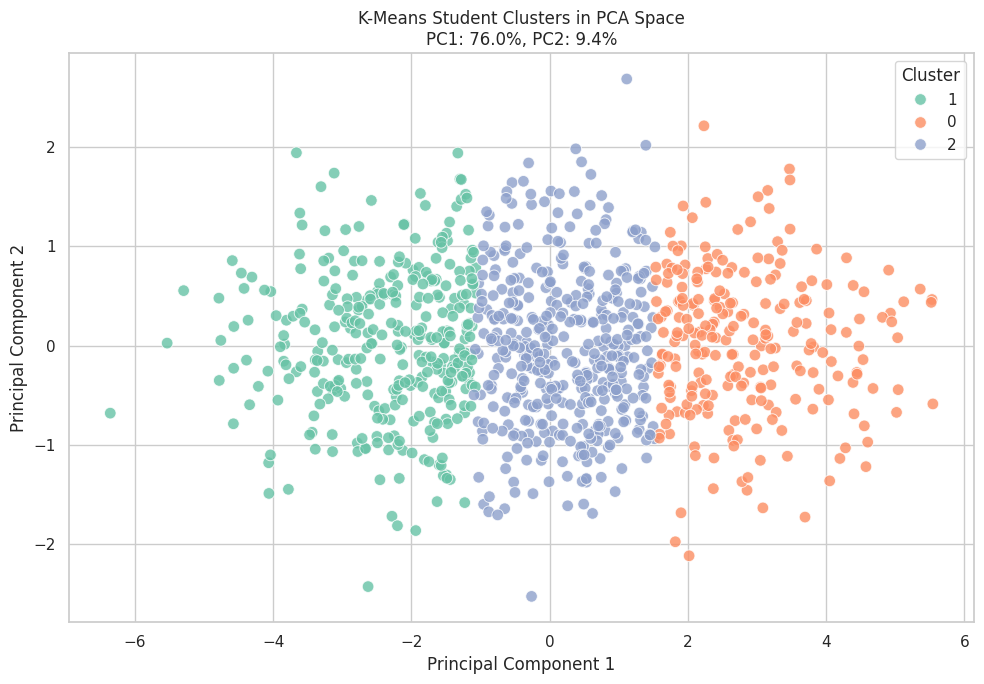

In [10]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_plot_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=df.index)
pca_plot_df["cluster"] = cluster_labels.astype(str)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_plot_df, x="PC1", y="PC2", hue="cluster",
    palette="Set2", s=70, alpha=0.8
)
plt.title(
    f"K-Means Student Clusters in PCA Space\n"
    f"PC1: {pca.explained_variance_ratio_[0]:.1%}, "
    f"PC2: {pca.explained_variance_ratio_[1]:.1%}"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 11. Interpret Cluster Profiles

The cluster-centre values are converted back to the original scale. Comparing these average values helps us describe each cluster.

In [11]:
centres_original_scale = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=feature_columns,
    index=[f"Cluster {i}" for i in range(optimal_k)]
)

print("Cluster centres in the original feature scale:")
display(centres_original_scale.round(2))

cluster_profile = clustered_df.groupby("cluster")[feature_columns].mean().round(2)
cluster_profile["student_count"] = clustered_df.groupby("cluster").size()

if target_column in clustered_df.columns:
    cluster_profile["pass_rate (%)"] = (
        clustered_df.groupby("cluster")[target_column].mean() * 100
    ).round(2)

print("Average profile of each cluster:")
display(cluster_profile)

Cluster centres in the original feature scale:


,test1_score,test2_score,final_exam_score,attendance_percentage,study_hours_per_week,assignments_submitted
Cluster 0,81.22,83.52,86.10,89.79,7.06,84.88
Cluster 1,49.24,51.25,53.21,75.94,2.09,56.08
Cluster 2,65.67,67.91,70.28,82.66,4.37,70.06


Average profile of each cluster:


,test1_score,test2_score,final_exam_score,attendance_percentage,study_hours_per_week,assignments_submitted,student_count,pass_rate (%)
cluster,,,,,,,,
0,81.22,83.52,86.10,89.79,7.06,84.88,242,100.00
1,49.24,51.25,53.21,75.94,2.09,56.08,334,51.20
2,65.67,67.91,70.28,82.66,4.37,70.06,424,98.35


## 12. Cluster Profile Chart

<Figure size 1200x600 with 0 Axes>

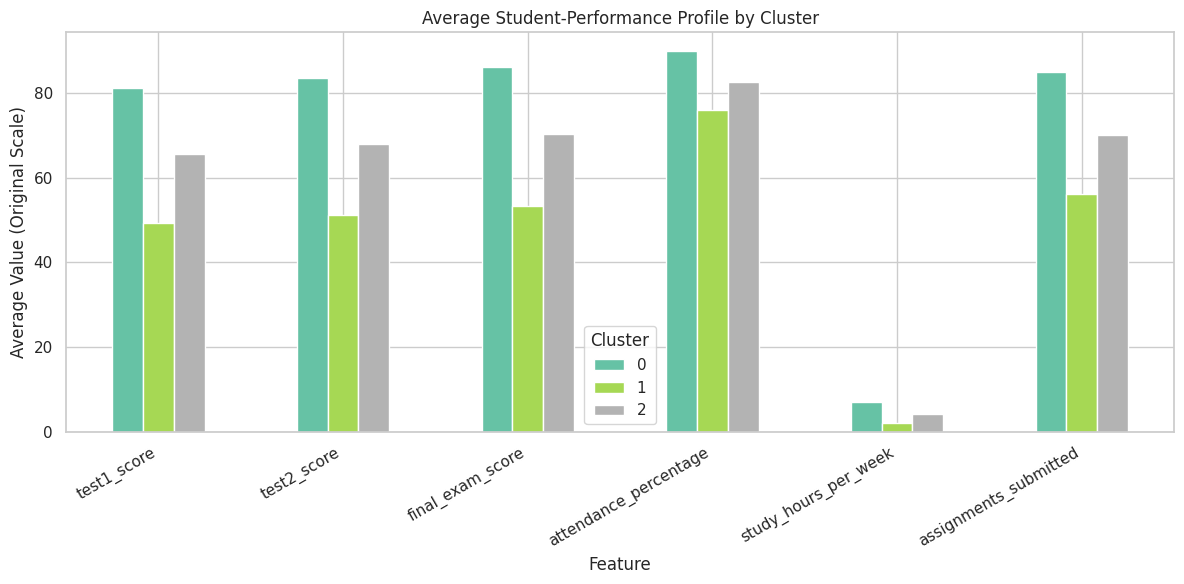

In [12]:
profile_for_plot = clustered_df.groupby("cluster")[feature_columns].mean().T

plt.figure(figsize=(12, 6))
profile_for_plot.plot(kind="bar", figsize=(12, 6), colormap="Set2")
plt.title("Average Student-Performance Profile by Cluster")
plt.xlabel("Feature")
plt.ylabel("Average Value (Original Scale)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 13. Compare Clusters with the Existing Pass/Fail Label

This comparison is optional and is not part of the K-Means training process. It helps check whether the unsupervised groups relate to the known pass/fail outcome.

In [13]:
if target_column in clustered_df.columns:
    comparison = pd.crosstab(
        clustered_df["cluster"],
        clustered_df[target_column],
        normalize="index"
    ) * 100
    comparison.columns = [f"Pass/Fail = {col} (%)" for col in comparison.columns]
    print("Percentage distribution of the original pass/fail label in each cluster:")
    display(comparison.round(2))
else:
    print("pass_fail column is not available for comparison.")

Percentage distribution of the original pass/fail label in each cluster:


,Pass/Fail = 0 (%),Pass/Fail = 1 (%)
cluster,,
0,0.00,100.00
1,48.80,51.20
2,1.65,98.35


## Result

K-Means clustering was successfully implemented on standardized Student Performance features. The students were grouped into $K$ clusters based on similarities in marks, attendance, study hours and assignment submission. The Elbow Method, Silhouette Score, PCA plot and cluster profiles were used to evaluate and interpret the clusters.

## Viva Questions

1. Is K-Means supervised or unsupervised learning?
2. Why is standardization important before K-Means?
3. What does the value of $K$ represent?
4. What is a centroid?
5. What is inertia in K-Means?
6. How does the Elbow Method help select $K$?
7. What does a high silhouette score indicate?
8. Why can different initial centroids lead to different clusters?
9. Why are identifier columns excluded from clustering?
10. What is the difference between K-Means clustering and K-Nearest Neighbours (KNN)?